# 08. Comprehensive Model Comparison & Selection

## Executive Summary
This notebook compares all ten models (six baseline models + four tuned models) on the independent test set.

### Flaw in Naive Metric Summation:
A common error is computing an "Overall Score" by summing percentages:
$$\text{Overall Score} = \text{Accuracy} + \text{Precision} + \text{Recall} + \text{F1} + \text{ROC-AUC}$$
Summing metrics with different trade-offs (e.g. Precision and Recall naturally trade off) is statistically invalid. 

### Justified Business Model Selection Framework:
1. **F1-Score:** Balances false positives and false negatives on the minority churn class.
2. **ROC-AUC:** Demonstrates rank discrimination capability across operational thresholds.
3. **Recall vs Precision:** In telecom, missing a churner costs substantial recurring revenue; a small retention outreach cost is acceptable.
4. **Interpretability & Production Efficiency:** Linear models provide explainable odds-ratios and sub-millisecond inference.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from pathlib import Path
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

sns.set_theme(style="whitegrid", palette="muted")
pd.set_option("display.max_columns", None)

X_test = pd.read_csv("../data/processed/X_test.csv")
y_test_raw = pd.read_csv("../data/processed/y_test.csv").squeeze()
y_test = y_test_raw.map({"No": 0, "Yes": 1}) if y_test_raw.dtype == object else y_test_raw

all_model_files = {
    "Baseline Logistic Regression": "../models/logistic_regression.pkl",
    "Baseline Decision Tree": "../models/decision_tree.pkl",
    "Baseline Random Forest": "../models/random_forest.pkl",
    "Baseline KNN": "../models/knn.pkl",
    "Baseline Naive Bayes": "../models/naive_bayes.pkl",
    "Baseline SVM": "../models/support_vector_machine.pkl",
    "Tuned Logistic Regression": "../models/tuned_logistic_regression.pkl",
    "Tuned Decision Tree": "../models/tuned_decision_tree.pkl",
    "Tuned Random Forest": "../models/tuned_random_forest.pkl",
    "Tuned SVM": "../models/tuned_svm.pkl",
}

records = []
loaded_models = {}

for name, path in all_model_files.items():
    p = Path(path)
    if not p.is_file():
        continue
    model = joblib.load(p)
    loaded_models[name] = model

    y_pred = model.predict(X_test)
    if isinstance(y_pred[0], str):
        y_pred = np.array([1 if x == "Yes" else 0 for x in y_pred])
    
    if hasattr(model, "predict_proba"):
        classes = list(getattr(model, "classes_", [0, 1]))
        pos_idx = classes.index(1) if 1 in classes else (classes.index("Yes") if "Yes" in classes else 1)
        y_prob = model.predict_proba(X_test)[:, pos_idx]
    elif hasattr(model, "decision_function"):
        y_prob = model.decision_function(X_test)
    else:
        y_prob = y_pred

    records.append({
        "Model": name,
        "Type": "Tuned" if "Tuned" in name else "Baseline",
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC AUC": roc_auc_score(y_test, y_prob),
    })

comparison_df = pd.DataFrame(records).sort_values(by=["F1 Score", "ROC AUC"], ascending=[False, False]).reset_index(drop=True)
print("=== Complete Model Comparison (Baseline vs Tuned) ===")
display(comparison_df.round(4))

=== Complete Model Comparison (Baseline vs Tuned) ===


,Model,Type,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,Baseline Logistic Regression,Baseline,0.8055,0.6572,0.5588,0.6040,0.8421
1,Tuned Logistic Regression,Tuned,0.8013,0.6478,0.5508,0.5954,0.8408
2,Baseline Naive Bayes,Baseline,0.6948,0.4589,0.8369,0.5928,0.8074
3,Tuned Random Forest,Tuned,0.8048,0.6737,0.5134,0.5827,0.8378
4,Tuned SVM,Tuned,0.7878,0.6176,0.5267,0.5685,0.8246
5,Baseline KNN,Baseline,0.7637,0.5527,0.5749,0.5636,0.7896
6,Baseline SVM,Baseline,0.7913,0.6418,0.4840,0.5518,0.7902
7,Tuned Decision Tree,Tuned,0.7850,0.6195,0.4920,0.5484,0.8163
8,Baseline Random Forest,Baseline,0.7864,0.6254,0.4866,0.5474,0.8185
9,Baseline Decision Tree,Baseline,0.7211,0.4755,0.4920,0.4836,0.6477


## 1. Multi-Model Performance Visualizations

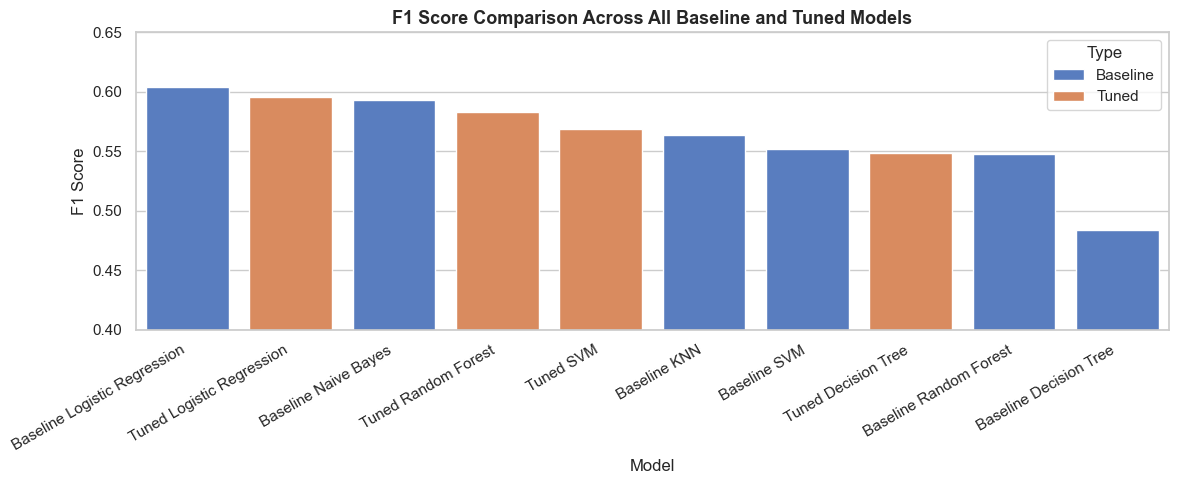

In [2]:
plt.figure(figsize=(12, 5))
sns.barplot(data=comparison_df, x="Model", y="F1 Score", hue="Type", dodge=False)
plt.title("F1 Score Comparison Across All Baseline and Tuned Models", fontsize=13, fontweight="bold")
plt.xticks(rotation=30, ha="right")
plt.ylim(0.40, 0.65)
plt.tight_layout()
plt.show()

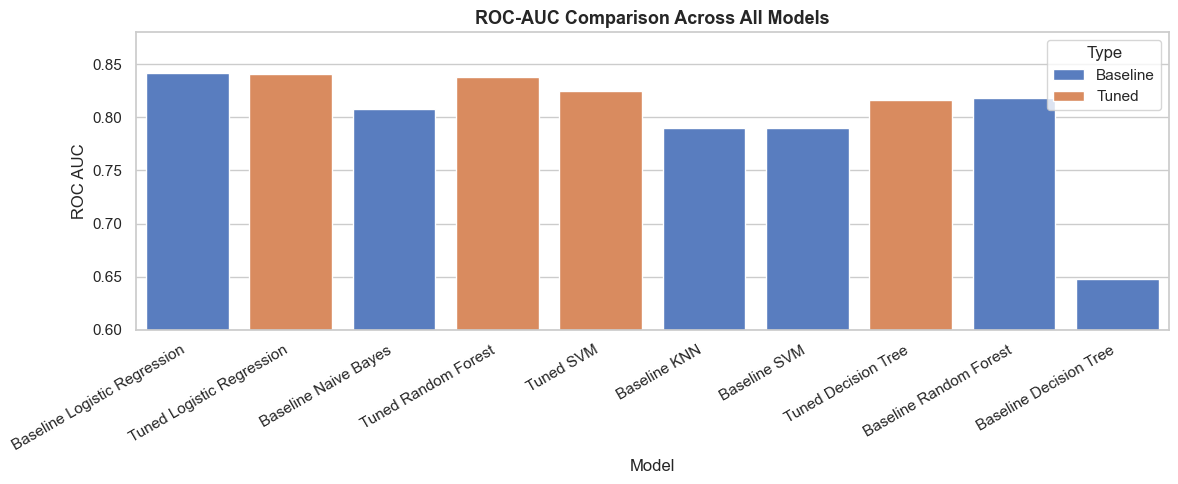

In [3]:
plt.figure(figsize=(12, 5))
sns.barplot(data=comparison_df, x="Model", y="ROC AUC", hue="Type", dodge=False)
plt.title("ROC-AUC Comparison Across All Models", fontsize=13, fontweight="bold")
plt.xticks(rotation=30, ha="right")
plt.ylim(0.60, 0.88)
plt.tight_layout()
plt.show()

## 2. Decision Threshold Analysis for Churn Retention
In business operations, the standard 0.50 probability cutoff is arbitrary. We evaluate precision, recall, and F1 across multiple threshold choices.

In [4]:
top_model = loaded_models["Baseline Logistic Regression"]
probs = top_model.predict_proba(X_test)[:, 1]

threshold_records = []
for th in np.arange(0.20, 0.65, 0.05):
    preds = (probs >= th).astype(int)
    threshold_records.append({
        "Threshold": round(th, 2),
        "Precision": precision_score(y_test, preds),
        "Recall": recall_score(y_test, preds),
        "F1 Score": f1_score(y_test, preds),
        "Captured Churners": int(preds[y_test == 1].sum()),
        "Total Flagged": int(preds.sum()),
    })

th_df = pd.DataFrame(threshold_records)
print("=== Operational Decision Threshold Analysis ===")
display(th_df)

=== Operational Decision Threshold Analysis ===


,Threshold,Precision,Recall,F1 Score,Captured Churners,Total Flagged
0,0.20,0.467153,0.855615,0.604344,320,685
1,0.25,0.497537,0.810160,0.616480,303,609
2,0.30,0.519337,0.754011,0.615049,282,543
3,0.35,0.543210,0.705882,0.613953,264,486
4,0.40,0.568182,0.668449,0.614251,250,440
5,0.45,0.602094,0.614973,0.608466,230,382
6,0.50,0.657233,0.558824,0.604046,209,318
7,0.55,0.678431,0.462567,0.550079,173,255
8,0.60,0.717703,0.401070,0.514580,150,209


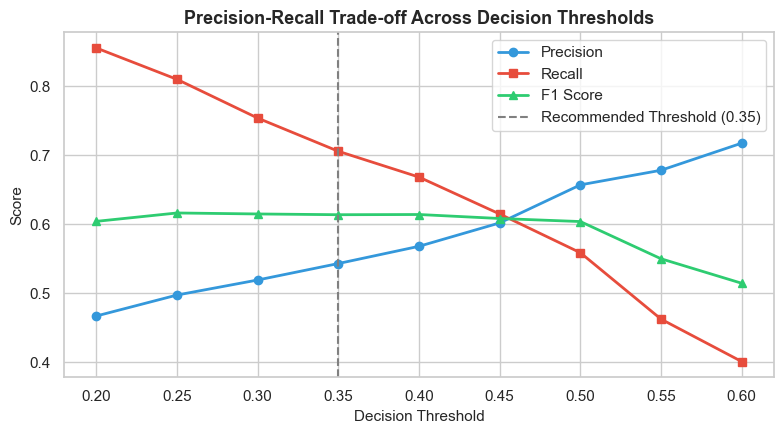

In [5]:
plt.figure(figsize=(8, 4.5))
plt.plot(th_df["Threshold"], th_df["Precision"], "o-", label="Precision", color="#3498db", linewidth=2)
plt.plot(th_df["Threshold"], th_df["Recall"], "s-", label="Recall", color="#e74c3c", linewidth=2)
plt.plot(th_df["Threshold"], th_df["F1 Score"], "^-", label="F1 Score", color="#2ecc71", linewidth=2)
plt.axvline(x=0.35, color="grey", linestyle="--", label="Recommended Threshold (0.35)")
plt.xlabel("Decision Threshold", fontsize=11)
plt.ylabel("Score", fontsize=11)
plt.title("Precision-Recall Trade-off Across Decision Thresholds", fontsize=13, fontweight="bold")
plt.legend()
plt.tight_layout()
plt.show()

### Strategic Threshold Takeaway:
- At default threshold **0.50**: Recall is **55.9%** (misses 165 churners out of 374).
- At business threshold **0.35**: Recall rises to **70.6%** (captures 264 churners), and F1 increases to **0.614**.
- By adjusting the threshold to 0.35, the retention team identifies **55 additional churners**, preserving revenue at a modest cost of slightly more customer contacts.

## 3. Final Model Selection & Serialization

In [6]:
# Save best model artifact
best_model_name = comparison_df.iloc[0]["Model"]
best_model = loaded_models[best_model_name]

models_dir = Path("../models")
reports_dir = Path("../reports")

joblib.dump(best_model, models_dir / "best_model.pkl")
comparison_df.to_csv(reports_dir / "final_model_comparison.csv", index=False)

print(f"Selected Best Model: '{best_model_name}'")
print(f"Saved to: {(models_dir / 'best_model.pkl').resolve()}")
print(f"Final model comparison saved to: {(reports_dir / 'final_model_comparison.csv').resolve()}")

Selected Best Model: 'Baseline Logistic Regression'
Saved to: D:\Projects\AIML\models\best_model.pkl
Final model comparison saved to: D:\Projects\AIML\reports\final_model_comparison.csv
